In [3]:

# ==========================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# STEP 2: DEFINE DATASET COLUMN NAMES
# ==========================================

columns = (
    ["unit", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# ==========================================
# STEP 3: LOAD NASA FD001 TRAINING DATA
# ==========================================

train_df = pd.read_csv(
    "../data/raw/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

# ==========================================
# STEP 4: DISPLAY FIRST FIVE ROWS
# ==========================================

train_df.head()


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [4]:
# Step 5: Check dataset dimensions

print("Dataset shape:", train_df.shape)

# Step 6: Check dataset information

train_df.info()

# Step 7: Statistical summary

train_df.describe()

Dataset shape: (20631, 26)
<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   unit       20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  flo

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


In [5]:
# Step 8: Count unique engines

total_engines = train_df["unit"].nunique()

print("Total number of engines:", total_engines)


# Step 9: Calculate operating cycles per engine

cycles_per_engine = train_df.groupby("unit")["cycle"].max()

print("\nOperating cycles per engine:")
print(cycles_per_engine.describe())

Total number of engines: 100

Operating cycles per engine:
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


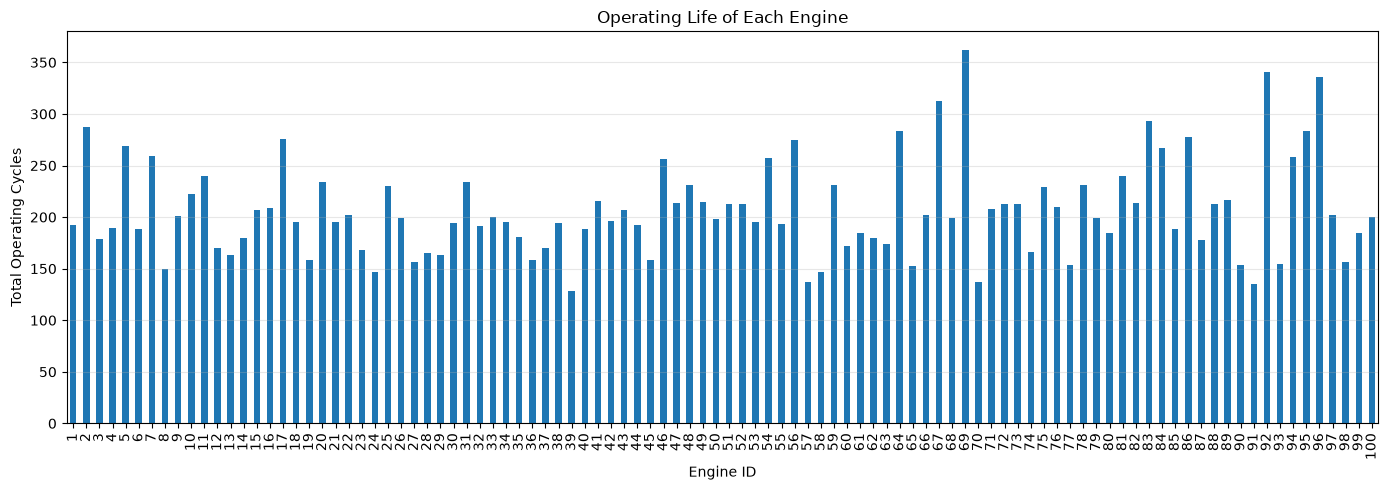

In [6]:
# Step 10: Visualize operating cycles of all engines

plt.figure(figsize=(14, 5))

cycles_per_engine.plot(kind="bar")

plt.title("Operating Life of Each Engine")
plt.xlabel("Engine ID")
plt.ylabel("Total Operating Cycles")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Step 11: Data quality checks

print("Missing values:", train_df.isnull().sum().sum())

print("Duplicate rows:", train_df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [8]:
# Step 13: Check the number of unique values in each sensor

sensor_columns = [col for col in train_df.columns if col.startswith("sensor_")]

sensor_variability = train_df[sensor_columns].nunique()

print("Unique values in each sensor:")
print(sensor_variability.sort_values())

Unique values in each sensor:
sensor_1        1
sensor_19       1
sensor_18       1
sensor_5        1
sensor_16       1
sensor_10       1
sensor_6        2
sensor_17      13
sensor_8       53
sensor_13      56
sensor_20     120
sensor_11     159
sensor_2      310
sensor_12     427
sensor_7      513
sensor_15    1918
sensor_3     3012
sensor_4     4051
sensor_21    4745
sensor_14    6078
sensor_9     6403
dtype: int64


In [9]:
# Step 15: Remove constant sensors

constant_sensors = sensor_variability[sensor_variability == 1].index.tolist()

train_df_clean = train_df.drop(columns=constant_sensors)

print("Removed sensors:", constant_sensors)
print("Original shape:", train_df.shape)
print("New shape:", train_df_clean.shape)

Removed sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Original shape: (20631, 26)
New shape: (20631, 20)


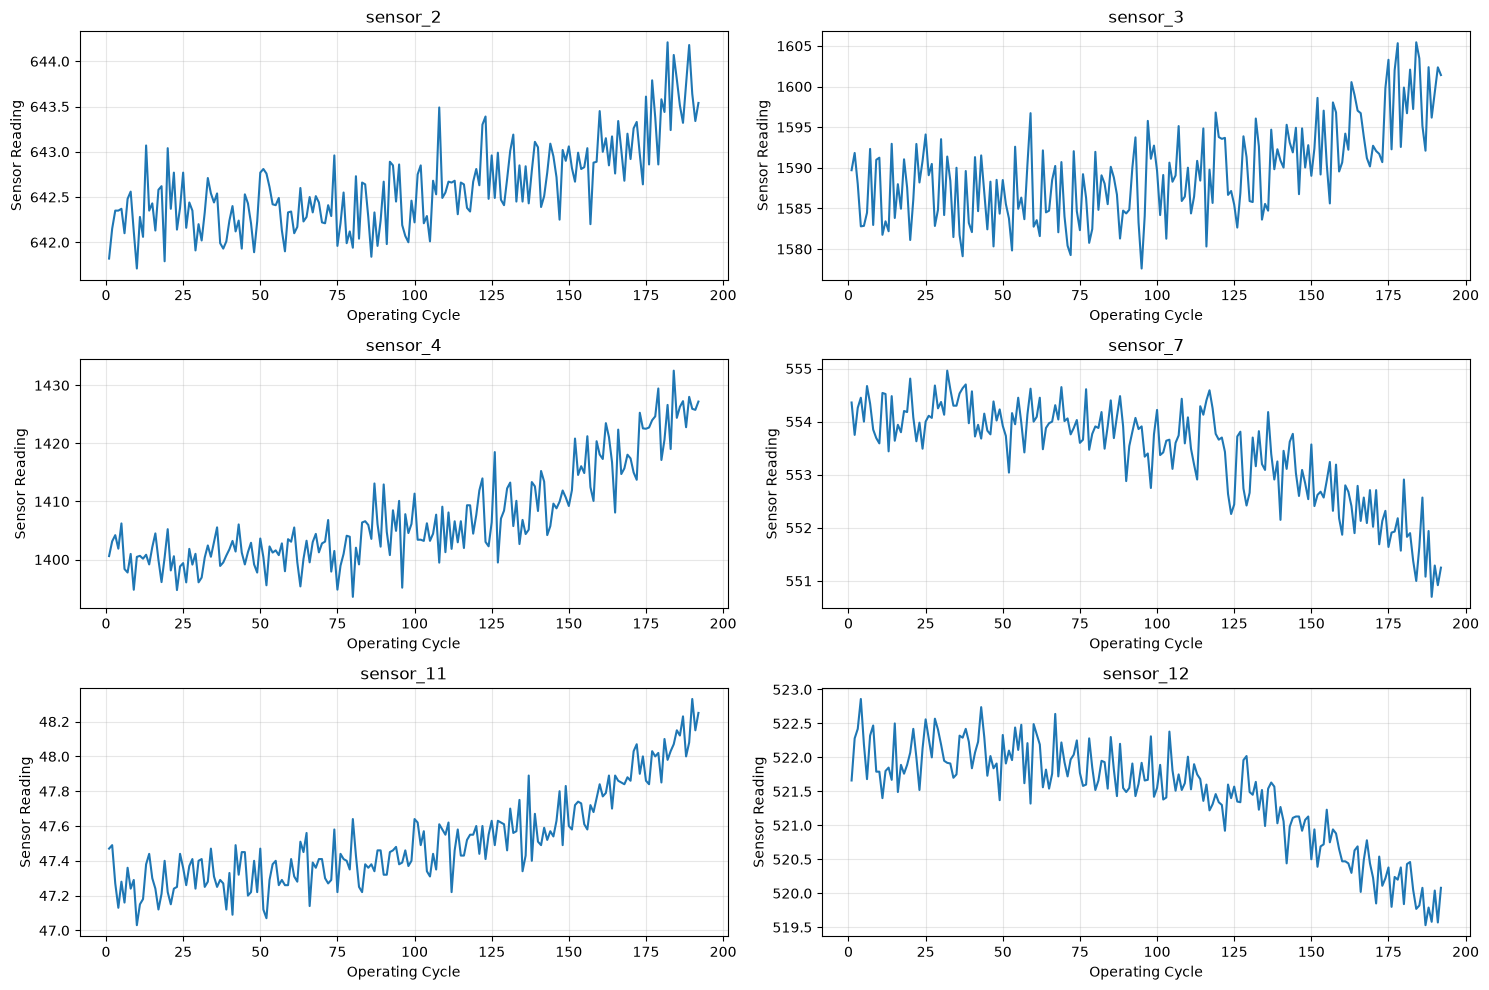

In [10]:
# Step 17: Visualize sensor behaviour for Engine 1

engine_1 = train_df_clean[train_df_clean["unit"] == 1]

selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12"
]

plt.figure(figsize=(15, 10))

for i, sensor in enumerate(selected_sensors, 1):
    plt.subplot(3, 2, i)
    plt.plot(engine_1["cycle"], engine_1[sensor])
    plt.title(sensor)
    plt.xlabel("Operating Cycle")
    plt.ylabel("Sensor Reading")
    plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

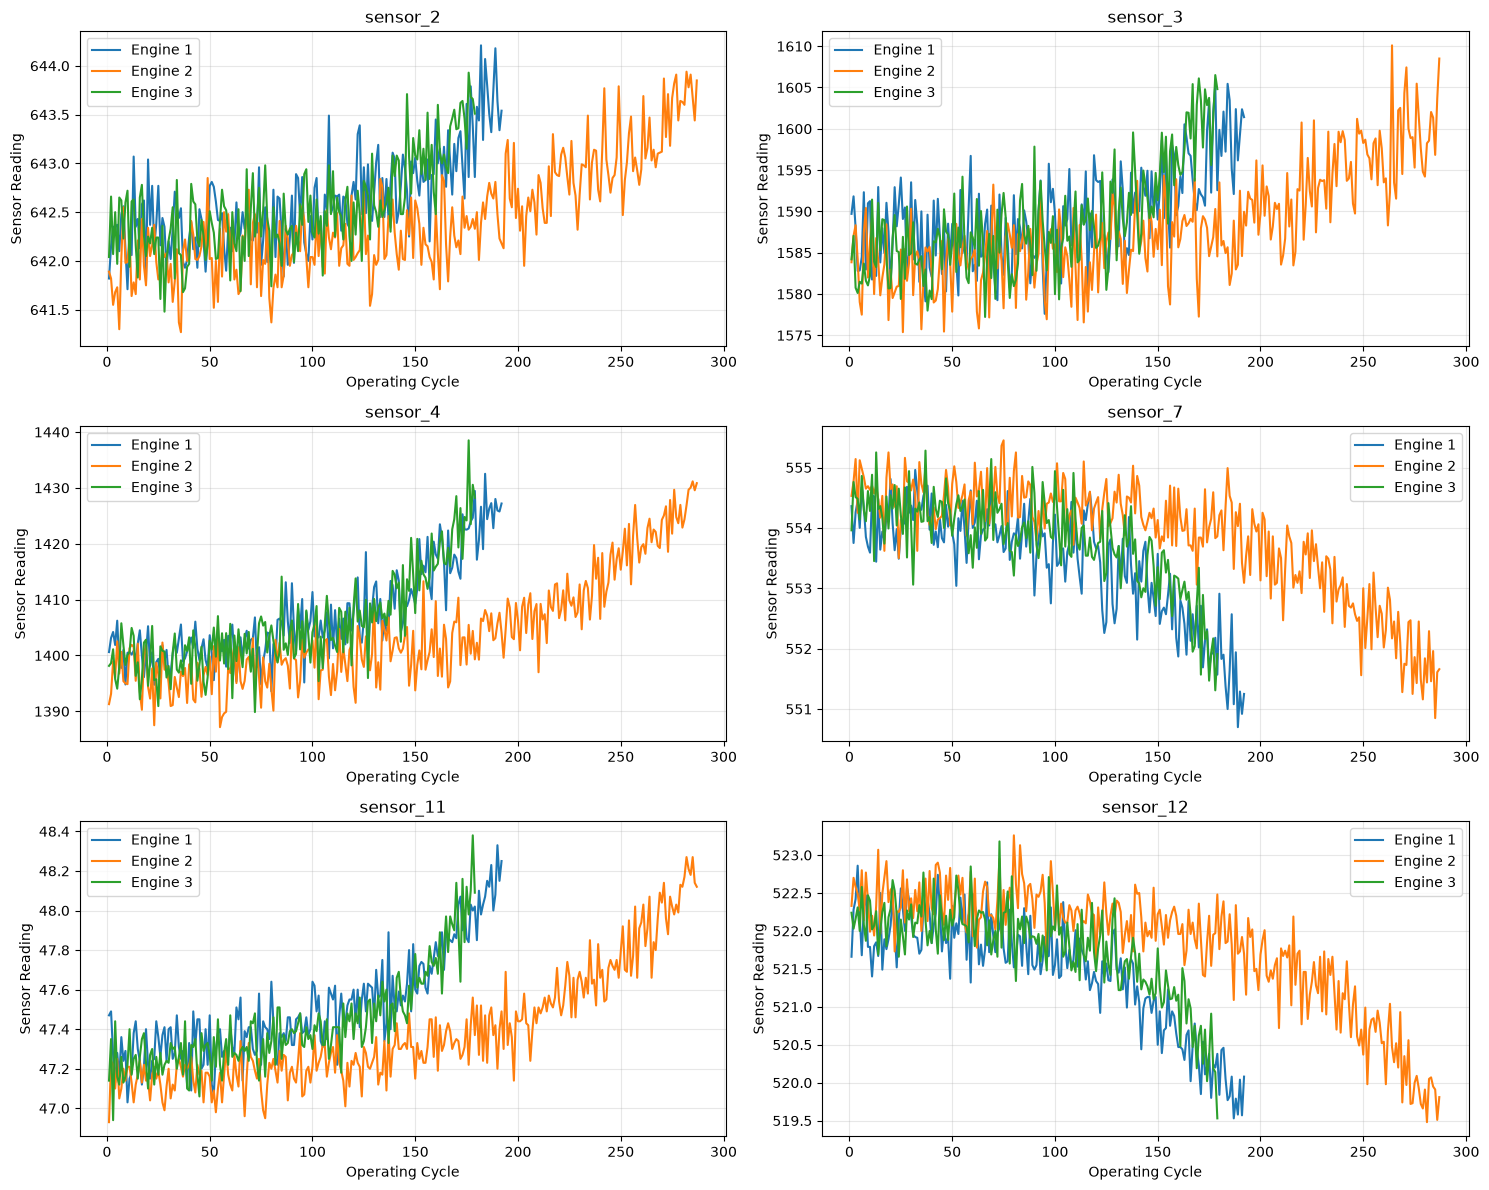

In [11]:
# Step 19: Compare sensor trends across three engines

selected_engines = [1, 2, 3]

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for i, sensor in enumerate(selected_sensors):

    ax = axes[i // 2, i % 2]

    for engine_id in selected_engines:

        engine_data = train_df_clean[
            train_df_clean["unit"] == engine_id
        ]

        ax.plot(
            engine_data["cycle"],
            engine_data[sensor],
            label=f"Engine {engine_id}"
        )

    ax.set_title(sensor)
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Sensor Reading")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
# Step 20: Calculate RUL for training data

max_cycles = train_df_clean.groupby("unit")["cycle"].max()

train_df_clean["RUL"] = (
    train_df_clean["unit"].map(max_cycles)
    - train_df_clean["cycle"]
)

# Display results
print(train_df_clean[["unit", "cycle", "RUL"]].head(10))

print("\nRUL statistics:")
print(train_df_clean["RUL"].describe())

   unit  cycle  RUL
0     1      1  191
1     1      2  190
2     1      3  189
3     1      4  188
4     1      5  187
5     1      6  186
6     1      7  185
7     1      8  184
8     1      9  183
9     1     10  182

RUL statistics:
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64


In [13]:
# Step 21: Cap RUL at 125 cycles

RUL_CAP = 125

train_df_clean["RUL"] = train_df_clean["RUL"].clip(upper=RUL_CAP)

print("Updated RUL statistics:")
print(train_df_clean["RUL"].describe())

print("\nSample RUL values:")
print(train_df_clean[["unit", "cycle", "RUL"]].head(10))

Updated RUL statistics:
count    20631.000000
mean        86.829286
std         41.673699
min          0.000000
25%         51.000000
50%        103.000000
75%        125.000000
max        125.000000
Name: RUL, dtype: float64

Sample RUL values:
   unit  cycle  RUL
0     1      1  125
1     1      2  125
2     1      3  125
3     1      4  125
4     1      5  125
5     1      6  125
6     1      7  125
7     1      8  125
8     1      9  125
9     1     10  125


In [14]:
# Step 22: Load test data and actual RUL labels

columns = (
    ["unit", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

test_df = pd.read_csv(
    "../data/raw/test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

test_rul = pd.read_csv(
    "../data/raw/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

# Remove the same six constant sensors
test_df = test_df.drop(columns=constant_sensors)

# Apply the same RUL cap to test labels
test_rul["RUL"] = test_rul["RUL"].clip(upper=125)

print("Test dataset shape:", test_df.shape)
print("Test engines:", test_df["unit"].nunique())
print("Actual RUL labels shape:", test_rul.shape)

print("\nTest data sample:")
print(test_df.head())

print("\nActual RUL sample:")
print(test_rul.head())

Test dataset shape: (13096, 20)
Test engines: 100
Actual RUL labels shape: (100, 1)

Test data sample:
   unit  cycle  setting_1  setting_2  setting_3  sensor_2  sensor_3  sensor_4  \
0     1      1     0.0023     0.0003      100.0    643.02   1585.29   1398.21   
1     1      2    -0.0027    -0.0003      100.0    641.71   1588.45   1395.42   
2     1      3     0.0003     0.0001      100.0    642.46   1586.94   1401.34   
3     1      4     0.0042     0.0000      100.0    642.44   1584.12   1406.42   
4     1      5     0.0014     0.0000      100.0    642.51   1587.19   1401.92   

   sensor_6  sensor_7  sensor_8  sensor_9  sensor_11  sensor_12  sensor_13  \
0     21.61    553.90   2388.04   9050.17      47.20     521.72    2388.03   
1     21.61    554.85   2388.01   9054.42      47.50     522.16    2388.06   
2     21.61    554.11   2388.05   9056.96      47.50     521.97    2388.03   
3     21.61    554.07   2388.03   9045.29      47.28     521.38    2388.05   
4     21.61    554.1

In [15]:
# Step 23: Engine-level split and feature scaling

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select operating settings and sensor columns
feature_columns = [
    col for col in train_df_clean.columns
    if col.startswith("setting_") or col.startswith("sensor_")
]

# Split engine IDs (not individual rows)
engine_ids = train_df_clean["unit"].unique()

train_units, val_units = train_test_split(
    engine_ids,
    test_size=0.20,
    random_state=42
)

# Separate training and validation engines
train_data = train_df_clean[
    train_df_clean["unit"].isin(train_units)
].copy()

val_data = train_df_clean[
    train_df_clean["unit"].isin(val_units)
].copy()

# Fit scaler ONLY on training data
scaler = StandardScaler()

train_data[feature_columns] = scaler.fit_transform(
    train_data[feature_columns]
)

# Apply the same scaler to validation and test data
val_data[feature_columns] = scaler.transform(
    val_data[feature_columns]
)

test_df[feature_columns] = scaler.transform(
    test_df[feature_columns]
)

print("Training engines:", train_data["unit"].nunique())
print("Validation engines:", val_data["unit"].nunique())
print("Test engines:", test_df["unit"].nunique())

print("\nFeature count:", len(feature_columns))
print("Training shape:", train_data.shape)
print("Validation shape:", val_data.shape)
print("Test shape:", test_df.shape)

Training engines: 80
Validation engines: 20
Test engines: 100

Feature count: 18
Training shape: (16561, 21)
Validation shape: (4070, 21)
Test shape: (13096, 20)


In [16]:
# Step 24: Create sliding windows

WINDOW_SIZE = 30

def create_windows(data, feature_columns, window_size=30):

    X, y = [], []

    for unit in data["unit"].unique():

        engine_data = data[data["unit"] == unit].sort_values("cycle")

        features = engine_data[feature_columns].values
        targets = engine_data["RUL"].values

        for i in range(len(engine_data) - window_size + 1):

            X.append(features[i:i + window_size])
            y.append(targets[i + window_size - 1])

    return np.array(X), np.array(y)


# Create training and validation windows
X_train, y_train = create_windows(train_data, feature_columns)
X_val, y_val = create_windows(val_data, feature_columns)

print("Training windows:", X_train.shape)
print("Training targets:", y_train.shape)

print("Validation windows:", X_val.shape)
print("Validation targets:", y_val.shape)

Training windows: (14241, 30, 18)
Training targets: (14241,)
Validation windows: (3490, 30, 18)
Validation targets: (3490,)


In [17]:
# Step 26: Convert data into PyTorch tensors

import torch
from torch.utils.data import TensorDataset, DataLoader

# Select device
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Using device:", device)

# Convert NumPy arrays into tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

# Create DataLoaders
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Input tensor shape:", X_train_tensor.shape)
print("Target tensor shape:", y_train_tensor.shape)

Using device: mps

Training batches: 112
Validation batches: 28
Input tensor shape: torch.Size([14241, 30, 18])
Target tensor shape: torch.Size([14241])


In [18]:
# Step 27: Build BiLSTM model

import torch.nn as nn

class BiLSTMModel(nn.Module):

    def __init__(self, input_size=18, hidden_size=64, num_layers=2):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size * 2, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        # Take the final time-step output
        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction.squeeze(1)


# Initialize model
bilstm_model = BiLSTMModel().to(device)

print(bilstm_model)

BiLSTMModel(
  (lstm): LSTM(18, 64, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)
